# Extracción de la vibración de un puente desde la aceleración medida en un carro con una CNN

**Objetivo:** evaluar si una red neuronal convolucional puede recuperar la vibración de un puente a partir de la aceleración registrada por un teléfono dentro de un carro que lo cruza.

## 1. Planteamiento físico

### 1.1 Sistema

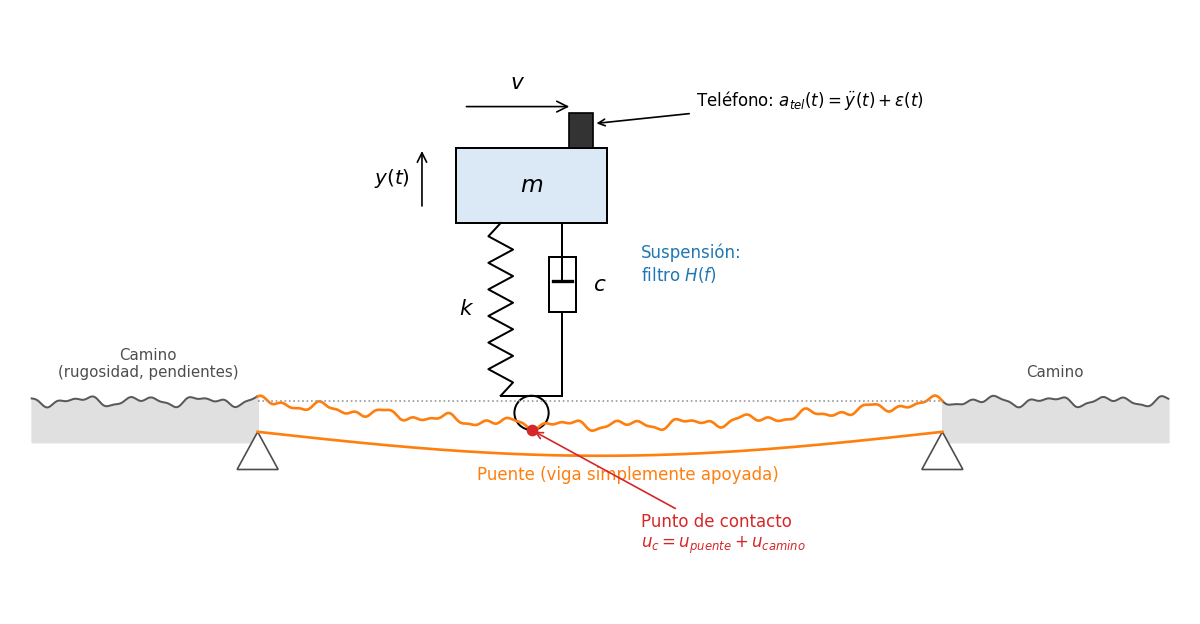

Carro simplificado de un grado de libertad (masa $m$, resorte $k$, amortiguador $c$) que cruza un puente simplemente apoyado a velocidad constante $v$, con camino rugoso antes, durante y después del puente.

### 1.2 Punto de contacto

La rueda sigue la superficie por donde pasa. El movimiento vertical bajo la rueda es la suma del puente y el camino:

$$u_c(t) = u_{\text{puente}}\big(x(t), t\big) + u_{\text{camino}}\big(x(t)\big), \qquad x(t) = v\,t$$

- $u_c(t)$: desplazamiento vertical del punto de contacto.
- $u_{\text{puente}}$: deflexión del puente en la posición de la rueda.
- $u_{\text{camino}}$: perfil del camino en esa posición (rugosidad y cambios de pendiente).
- $x(t)$: posición de la rueda.

### 1.3 El carro como filtro

El punto de contacto excita al carro desde abajo:

$$m\,\ddot y + c\,(\dot y - \dot u_c) + k\,(y - u_c) = 0$$

- $y(t)$: desplazamiento vertical de la carrocería, donde va el teléfono.

### 1.4 Señal medida

Combinando lo anterior, la aceleración registrada por el teléfono es:

$$a_{\text{tel}}(t) = \ddot y(t) + \varepsilon(t)$$

- $\varepsilon(t)$: ruido del sensor.

## 2. Problema

Recuperar $\ddot u_{\text{puente}}(t)$ a partir de $a_{\text{tel}}(t)$ implica dos pasos:

1. **Deshacer el efecto dinámico del carro:** pasar de $a_{\text{tel}}$ a $\ddot u_c$. Requiere conocer $m$, $c$ y $k$ (Yang et al., 2019), desconocidos en un carro cualquiera.
2. **Separar el puente del camino:** dentro de $\ddot u_c$, aislar $\ddot u_{\text{puente}}$ de $\ddot u_{\text{camino}}$.

## 3. Propuesta

Una CNN que resuelve los dos pasos a la vez, sin conocer $m$, $c$ ni $k$, aprendiendo de muchos carros y puentes simulados:

$$\hat{\ddot u}_{\text{puente}}(t) = f_\theta\big(a_{\text{tel}}(t)\big)$$

| | Contenido |
|---|---|
| Entrada | $a_{\text{tel}}(t)$: aceleracion medida en el telefono |
| Salida | $\ddot u_{\text{puente}}(t)$: aceleración del puente bajo la rueda |
| Modelo $f_\theta$ | Convolutional Neural Network (CNN) |

Objetivo en el punto de contacto: contiene las frecuencias del puente y no la del carro (Yang et al., 2019).

Opción adicional: como el mayor desafio para la CNN es aprender el efecto dinámico del carro sin conocer sus propiedades, se podría incluir como entrada el tramo antes del puente, como contexto para "calibrar" el carro.

### 3.1 Idea general de una CNN 1D

Un kernel (un segmento corto de pesos) recorre la señal a lo largo del tiempo y responde con más fuerza donde encuentra el patrón que aprendió. En el ejemplo ilustrativo, un kernel con forma de oscilación del puente resalta el tramo en que el carro está sobre el puente (2–8 s):

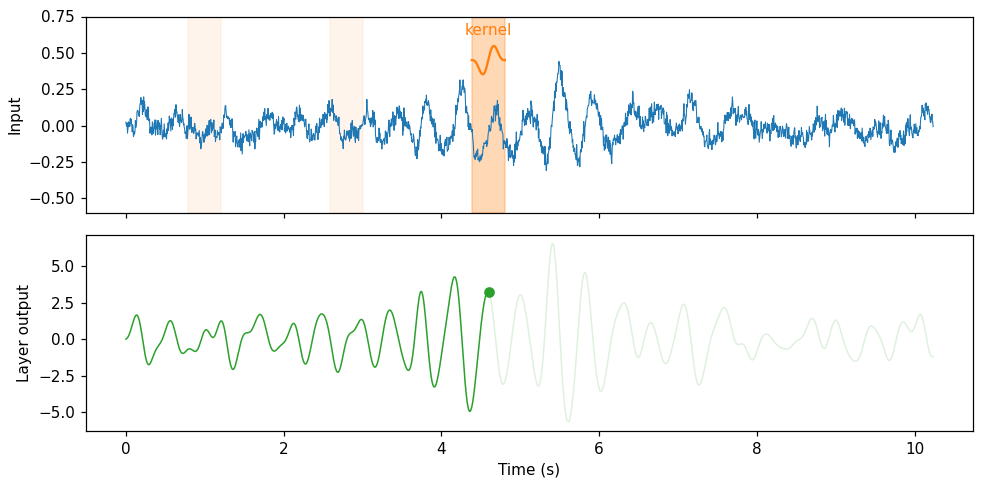

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- Synthetic phone signal (illustration only) ----------
fs = 200.0
t = np.arange(0, 10.24, 1 / fs)
rng = np.random.default_rng(0)
on_bridge = (t > 2.0) & (t < 8.0)
bridge = 0.15 * np.sin(2 * np.pi * 2.4 * t) * np.sin(np.pi * (t - 2.0) / 6.0) * on_bridge
road = np.convolve(rng.normal(0, 1, t.size), np.ones(25) / 25, mode="same") * 0.3
car = 0.05 * np.sin(2 * np.pi * 1.7 * t + 0.5)
signal = bridge + road + car + rng.normal(0, 0.03, t.size)

def cross_corr(x, kern):
    """Cross-correlation as used in CNN layers ('same' padding)."""
    return np.correlate(x, kern, mode="same")

# ---------- One kernel sliding along the signal ----------
kern_osc = np.sin(2 * np.pi * 2.4 * np.arange(-42, 43) / fs) * np.hanning(85)   # oscillation pattern
out = cross_corr(signal, kern_osc)
t_now = 4.6                                                                      # current kernel position
i_now = int(t_now * fs)
half = len(kern_osc) // 2

fig, ax = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
ax[0].plot(t, signal, lw=0.7, color="tab:blue")
for tc, alpha in [(1.0, 0.08), (2.8, 0.08), (t_now, 0.3)]:
    ax[0].axvspan(tc - half / fs, tc + half / fs, color="tab:orange", alpha=alpha)
ax[0].plot(t[i_now - half:i_now + half + 1], kern_osc * 0.15 + 0.45, color="tab:orange", lw=1.5)
ax[0].text(t_now, 0.62, "kernel", ha="center", color="tab:orange")
ax[0].set_ylabel("Input"); ax[0].set_ylim(-0.6, 0.75)
ax[1].plot(t[:i_now + 1], out[:i_now + 1], color="tab:green", lw=1)
ax[1].plot(t[i_now:], out[i_now:], color="tab:green", lw=1, alpha=0.15)
ax[1].plot(t_now, out[i_now], "o", color="tab:green")
ax[1].set_ylabel("Layer output"); ax[1].set_xlabel("Time (s)")
fig.tight_layout()
plt.show()

Una capa tiene varios kernels, cada uno atento a un patrón distinto, y al apilar capas la red combina esos patrones en otros más complejos hasta reconstruir la vibración del puente.

## 4. Datos

Señales simuladas con un simulador vehículo-puente, en versión simplificada:

| Elemento | Simplificación |
|---|---|
| Puente | Viga simplemente apoyada, luces de 15 a 60 m |
| Carro | 1 grado de libertad, frecuencia propia de 1 a 3 Hz (la misma utilizada en Talebi-Kalaleh y Mei, 2026) * |
| Interacción | Desacoplada: carro como carga móvil, válida si la masa del carro ≪ masa del puente (Yang et al., 2019; Talebi-Kalaleh y Mei, 2026) |
| Camino | Rugosidad ISO 8608 (Agostinacchio et al., 2014; Talebi-Kalaleh y Mei, 2026) |
| Teléfono | Ruido blanco, 200 Hz |
| Excluido | Motor, cabeceo, soporte del teléfono |

Entre 2.000 y 5.000 señales, cada una con puente, carro y velocidad distintos. Ejemplo de un cruce:

*Nota: Por confirmar fuentes que respalden que las frecuencias de los autos están en ese rango. 

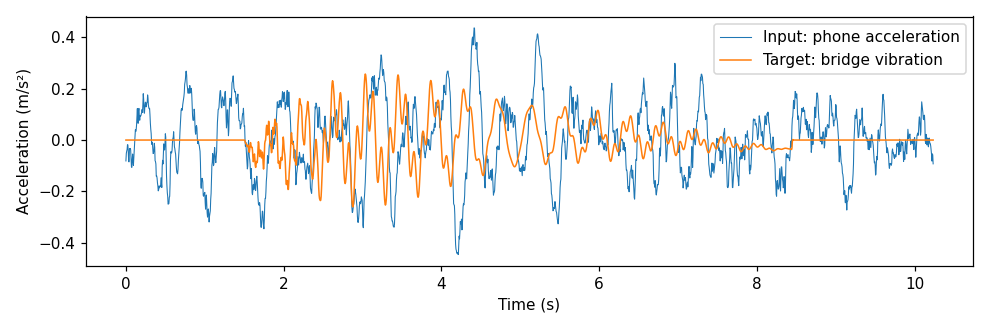

In [3]:
import vehicle_bridge_signal as vbs

# One simulated crossing (simplified car and bridge)
cfg = vbs.load_preset("snr_controlled_dataset", {"vehicle.model": "sprung_mass",
                                                 "simulation.interaction": "decoupled",
                                                 "engine.enabled": False})
scenario, seed = vbs.sample_scenario(cfg, seed=7)
res = vbs.simulate(scenario, seed)

a_tel = res.measured                                                              # model input
a_bridge = sum(res.contact[k][0] for k in res.contact if k.startswith("bridge"))  # model target

plt.figure(figsize=(9, 3))
plt.plot(res.t, a_tel, lw=0.7, label="Input: phone acceleration")
plt.plot(res.t, a_bridge, lw=1.0, label="Target: bridge vibration")
plt.xlabel("Time (s)"); plt.ylabel("Acceleration (m/s²)"); plt.legend()
plt.show()